# Document Classification Using NLP and Machine Learning
## 20 Newsgroups Dataset

**Project objective:** Train and evaluate machine-learning models that classify text documents into one of 20 newsgroup categories.

**Workflow:** Load dataset → explore data → preprocess text → TF-IDF feature extraction → train models → evaluate → save the best model → classify new text.



## 1. Install and import required libraries


In [18]:

%pip install pandas numpy scikit-learn matplotlib seaborn joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import re
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the 20 Newsgroups dataset


In [5]:
newsgroups = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=42
)

X = pd.Series(newsgroups.data, name="text")
y = pd.Series(newsgroups.target, name="target")
target_names = newsgroups.target_names

df = pd.DataFrame({
    "text": X,
    "category": y.map(lambda label: target_names[label])
})

print("Dataset loaded successfully.")
print("Number of documents:", len(df))
print("Number of categories:", len(target_names))
df.head()

Dataset loaded successfully.
Number of documents: 18846
Number of categories: 20


,text,category
0,\n\nI am sure some bashers of Pens fans are pr...,rec.sport.hockey
1,My brother is in the market for a high-perform...,comp.sys.ibm.pc.hardware
2,\n\n\n\n\tFinally you said what you dream abou...,talk.politics.mideast
3,\nThink!\n\nIt's the SCSI card doing the DMA t...,comp.sys.ibm.pc.hardware
4,1) I have an old Jasmine drive which I cann...,comp.sys.mac.hardware


## 3. Explore the dataset

Category names:
- alt.atheism
- comp.graphics
- comp.os.ms-windows.misc
- comp.sys.ibm.pc.hardware
- comp.sys.mac.hardware
- comp.windows.x
- misc.forsale
- rec.autos
- rec.motorcycles
- rec.sport.baseball
- rec.sport.hockey
- sci.crypt
- sci.electronics
- sci.med
- sci.space
- soc.religion.christian
- talk.politics.guns
- talk.politics.mideast
- talk.politics.misc
- talk.religion.misc
\nDocuments per category:


,document_count
category,
alt.atheism,799
comp.graphics,973
comp.os.ms-windows.misc,985
comp.sys.ibm.pc.hardware,982
comp.sys.mac.hardware,963
comp.windows.x,988
misc.forsale,975
rec.autos,990
rec.motorcycles,996


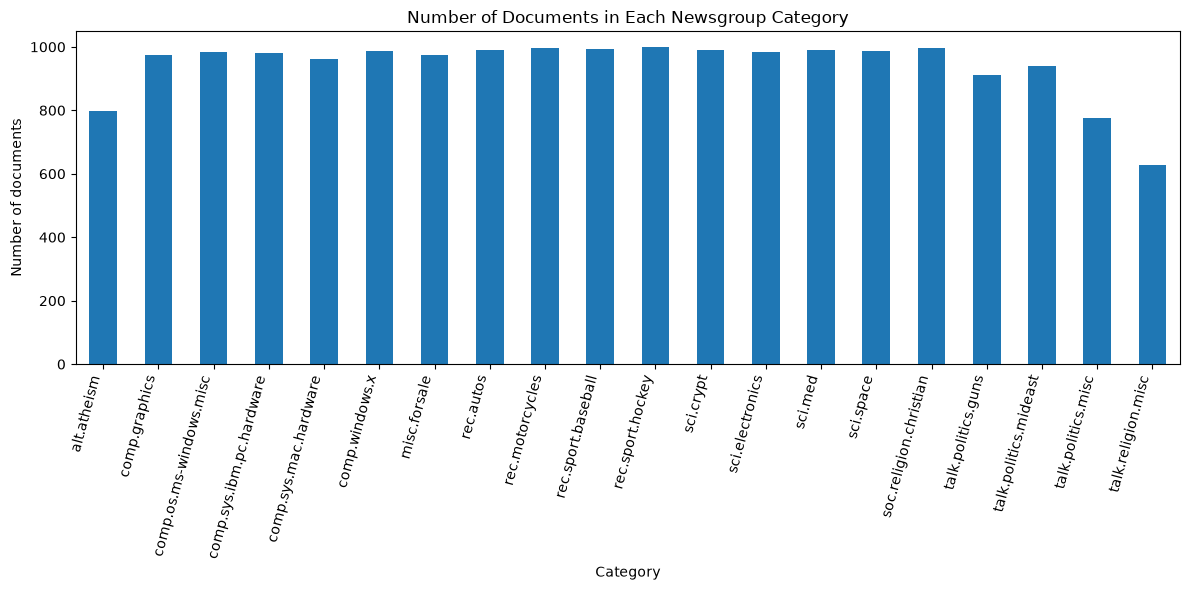

In [6]:
print("Category names:")
for category in target_names:
    print("-", category)

print("\\nDocuments per category:")
display(df["category"].value_counts().sort_index().to_frame("document_count"))

plt.figure(figsize=(12, 6))
df["category"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Documents in Each Newsgroup Category")
plt.xlabel("Category")
plt.ylabel("Number of documents")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## 4. Text preprocessing
This basic cleaning function lowercases text, removes URLs, email addresses, and most punctuation, and normalizes extra spaces. TF-IDF will handle tokenization and stop-word filtering.

In [7]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\\S+|www\\.\\S+", " ", text)  # URLs
    text = re.sub(r"\\b[\\w.+-]+@[\\w.-]+\\.[a-z]{2,}\\b", " ", text)  # email addresses
    text = re.sub(r"[^a-z\\s]", " ", text)  # keep letters and spaces
    text = re.sub(r"\\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
display(df[["category", "text", "clean_text"]].head(3))

,category,text,clean_text
0,rec.sport.hockey,\n\nI am sure some bashers of Pens fans are pr...,i am sure some bashers of pens fans are pretty...
1,comp.sys.ibm.pc.hardware,My brother is in the market for a high-perform...,my brother is in the market for a high perform...
2,talk.politics.mideast,\n\n\n\n\tFinally you said what you dream abou...,finally you said what you dream about mediter...


## 5. Split data into training and testing sets
The test set is held back until evaluation. Stratification keeps category proportions similar in both sets.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"],
    df["category"],
    test_size=0.20,
    random_state=42,
    stratify=df["category"]
)

print("Training documents:", len(X_train))
print("Testing documents:", len(X_test))

Training documents: 15076
Testing documents: 3770


## 6. Convert text into numerical features using TF-IDF
TF-IDF gives higher weight to words that are informative in a document and less weight to words that occur frequently across many documents.

In [9]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (15076, 50000)
Testing TF-IDF shape: (3770, 50000)


## 7. Train and compare machine-learning models
We compare Multinomial Naive Bayes, Logistic Regression, and Linear Support Vector Machine (LinearSVC).

In [12]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42)
}

results = []
trained_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)
    accuracy = accuracy_score(y_test, predictions)

    trained_models[model_name] = model
    results.append({
        "Model": model_name,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df)

Training Multinomial Naive Bayes...
Training Logistic Regression...
Training Linear SVM...


,Model,Accuracy
2,Linear SVM,0.766048
1,Logistic Regression,0.748011
0,Multinomial Naive Bayes,0.729443


## 8. Visualize model comparison

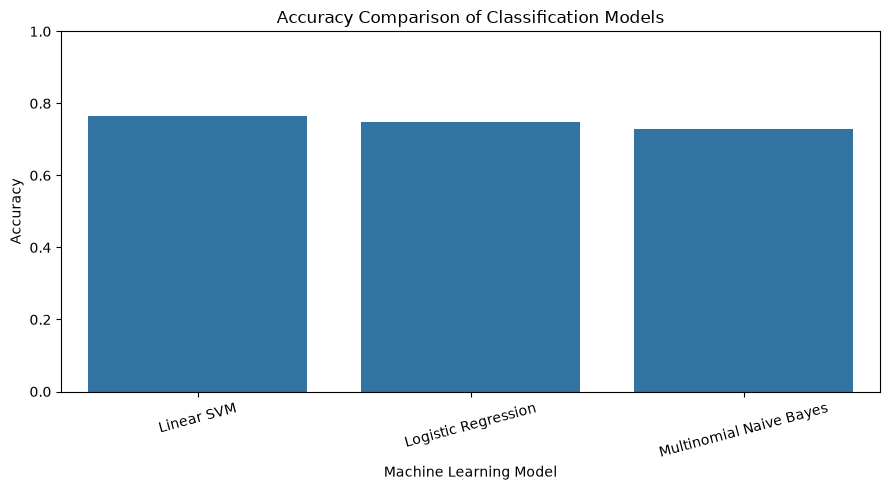

In [11]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Accuracy Comparison of Classification Models")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 9. Select the best model and evaluate it
The model with the highest test accuracy is selected from the comparison above.

In [13]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test_tfidf)

print("Best model:", best_model_name)
print("Test accuracy: {:.2f}%".format(accuracy_score(y_test, y_pred) * 100))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Best model: Linear SVM
Test accuracy: 76.60%
\nClassification report:
                          precision    recall  f1-score   support

             alt.atheism       0.67      0.59      0.63       160
           comp.graphics       0.74      0.74      0.74       195
 comp.os.ms-windows.misc       0.72      0.74      0.73       197
comp.sys.ibm.pc.hardware       0.68      0.70      0.69       196
   comp.sys.mac.hardware       0.79      0.72      0.75       193
          comp.windows.x       0.89      0.88      0.89       198
            misc.forsale       0.81      0.76      0.78       195
               rec.autos       0.52      0.85      0.65       198
         rec.motorcycles       0.82      0.71      0.76       199
      rec.sport.baseball       0.91      0.84      0.87       199
        rec.sport.hockey       0.93      0.89      0.91       200
               sci.crypt       0.90      0.83      0.86       198
         sci.electronics       0.73      0.78      0.76       197
     

## 10. Confusion matrix
A confusion matrix shows correct and incorrect predictions for each category.

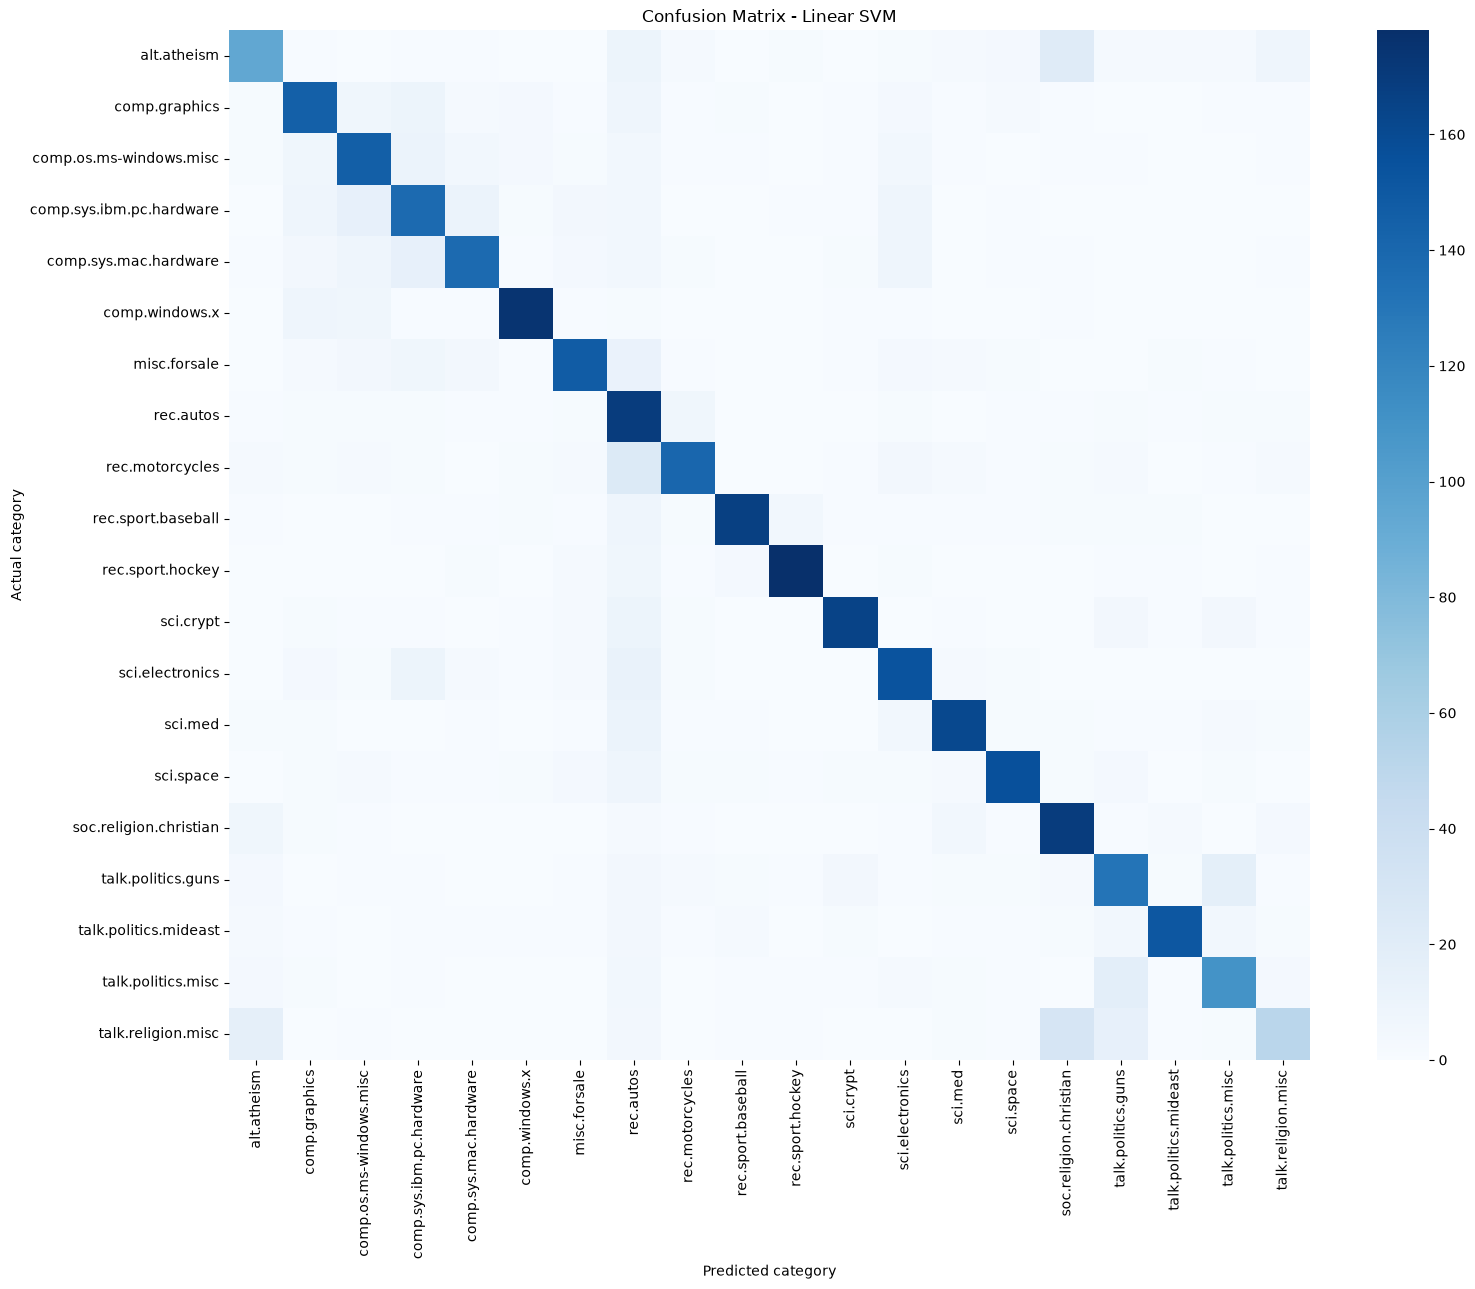

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=target_names)

plt.figure(figsize=(16, 13))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title("Confusion Matrix - " + best_model_name)
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Save the trained model and TF-IDF vectorizer
The saved files can be reused later in a separate application without retraining.

In [15]:
os.makedirs("Models", exist_ok=True)

joblib.dump(best_model, "Models/best_document_classifier.pkl")
joblib.dump(tfidf, "Models/tfidf_vectorizer.pkl")
joblib.dump(target_names, "Models/category_names.pkl")

print("Model, vectorizer, and category names saved in the Models folder.")

Model, vectorizer, and category names saved in the Models folder.


In [19]:
import joblib

model = joblib.load("Models/best_document_classifier.pkl")
vectorizer = joblib.load("Models/tfidf_vectorizer.pkl")
categories = joblib.load("Models/category_names.pkl")

print("Model loaded successfully!")
print("Vectorizer loaded successfully!")
print("Categories:", categories)

Model loaded successfully!
Vectorizer loaded successfully!
Categories: ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


## 12. Test the model with your own document text


In [16]:
sample_document = """
NASA scientists are studying a new space telescope and the planets
that orbit distant stars. The mission will collect images and data
to help researchers understand the universe.
"""

cleaned_sample = clean_text(sample_document)
sample_vector = tfidf.transform([cleaned_sample])
predicted_category = best_model.predict(sample_vector)[0]

print("Input document:")
print(sample_document)
print("\\nPredicted category:", predicted_category)

Input document:

NASA scientists are studying a new space telescope and the planets
that orbit distant stars. The mission will collect images and data
to help researchers understand the universe.

\nPredicted category: sci.space


## 13. Predict the category of multiple documents


In [17]:
sample_documents = [
    "The computer graphics card improves image rendering and gaming performance.",
    "The team scored a goal in the final minutes of the football match.",
    "The government announced a new policy after the election."
]

cleaned_documents = [clean_text(text) for text in sample_documents]
document_vectors = tfidf.transform(cleaned_documents)
predicted_categories = best_model.predict(document_vectors)

predictions_df = pd.DataFrame({
    "Document": sample_documents,
    "Predicted category": predicted_categories
})
display(predictions_df)

,Document,Predicted category
0,The computer graphics card improves image rend...,comp.graphics
1,The team scored a goal in the final minutes of...,rec.sport.hockey
2,The government announced a new policy after th...,talk.politics.mideast


## 14. Project conclusion

In this project, we used the 20 Newsgroups dataset to build a multi-class document classification system. We cleaned text, converted it into TF-IDF features, trained three machine-learning algorithms, compared their performance, and evaluated the selected model using accuracy, a classification report, and a confusion matrix.

